In [ ]:
("My OIST Research Project")
print("Data-Efficient Machine Learning Using Optimal Transport")
print("Project started successfully!")print

My OIST Research Project
Data-Efficient Machine Learning Using Optimal Transport
Project started successfully!


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

# Define the random state seed
SEED = 42

# Load and prepare dataset to ensure variables exist
data = load_breast_cancer()
X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=SEED,
    stratify=y
)

# Scale features using training data only
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Helper function to initialize models
def build_models():
    return {
        "Logistic Regression": LogisticRegression(max_iter=2000, random_state=SEED),
        "RBF-SVM": SVC(kernel="rbf", probability=True, random_state=SEED),
        "KNN": KNeighborsClassifier(n_neighbors=5)
    }

# Use training data only; keep the locked test set untouched.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

cv_rows = []

scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

for model_name, model in build_models().items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    cv_rows.append({
        "model": model_name,
        "accuracy_mean": scores["test_accuracy"].mean(),
        "accuracy_std": scores["test_accuracy"].std(),
        "balanced_accuracy_mean": scores["test_balanced_accuracy"].mean(),
        "f1_mean": scores["test_f1"].mean(),
        "roc_auc_mean": scores["test_roc_auc"].mean()
    })

cv_results = pd.DataFrame(cv_rows)
display(cv_results.round(4))

cv_results.to_csv("five_fold_cross_validation.csv", index=False)
print("Saved five_fold_cross_validation.csv")

,model,accuracy_mean,accuracy_std,balanced_accuracy_mean,f1_mean,roc_auc_mean
0,Logistic Regression,0.9780,0.0098,0.9753,0.9825,0.9957
1,RBF-SVM,0.9670,0.0155,0.9642,0.9738,0.9957
2,KNN,0.9604,0.0112,0.9530,0.9688,0.9879


Saved five_fold_cross_validation.csv


In [ ]:

!pip -q install POT



In [ ]:

import ot
print("POT version:", ot.__version__)
print("Optimal Transport library installed successfully!")



POT version: 0.9.7.post1
Optimal Transport library installed successfully!


In [ ]:

# Check whether the dataset and training variables exist

required_variables = [
    "X_train", "X_test", "y_train", "y_test"
]

for variable in required_variables:
    print(f"{variable}:",
          "Available" if variable in globals() else "Missing")


X_train: Available
X_test: Available
y_train: Available
y_test: Available


In [ ]:

import numpy as np
import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Load the dataset
data = load_breast_cancer()
X = data.data
y = data.target

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Scale features using training data only
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Dataset prepared successfully!")
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])
print("Training labels:", np.unique(y_train))
print("Testing labels:", np.unique(y_test))


Dataset prepared successfully!
Training samples: 455
Testing samples: 114
Number of features: 30
Training labels: [0 1]
Testing labels: [0 1]


In [ ]:

import ot
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# Model A: Logistic Regression
lr = LogisticRegression(max_iter=2000, random_state=42)
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)

# Model B: OT-based class-distribution classifier
classes = np.unique(y_train)
class_distributions = {
    label: X_train[y_train == label][:100]
    for label in classes
}

pred_ot = []

for sample in X_test:
    costs = []

    for label in classes:
        class_samples = class_distributions[label]

        # Uniform probability weights
        a = np.ones(len(class_samples)) / len(class_samples)
        b = np.array([1.0])

        # Squared Euclidean cost from class samples to test sample
        cost_matrix = ot.dist(
            class_samples,
            sample.reshape(1, -1),
            metric="sqeuclidean"
        )

        # Optimal transport cost
        plan = ot.emd(a, b, cost_matrix)
        transport_cost = np.sum(plan * cost_matrix)

        costs.append(transport_cost)

    pred_ot.append(classes[np.argmin(costs)])

# Evaluate both models
print("LOGISTIC REGRESSION")
print("Accuracy:", round(accuracy_score(y_test, pred_lr), 4))
print("F1-score:", round(f1_score(y_test, pred_lr), 4))

print("\nOT-BASED CLASSIFIER")
print("Accuracy:", round(accuracy_score(y_test, pred_ot), 4))
print("F1-score:", round(f1_score(y_test, pred_ot), 4))


LOGISTIC REGRESSION
Accuracy: 0.9825
F1-score: 0.9861

OT-BASED CLASSIFIER
Accuracy: 0.9298
F1-score: 0.9474


In [ ]:
import numpy as np
import ot
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Evaluate performance across different fractions of training data
for fraction in [0.1, 0.2, 0.4, 0.6, 0.8, 1.0]:
    # Determine sub-sample size
    n_samples = int(len(X_train) * fraction)
    X_train_sub = X_train[:n_samples]
    y_train_sub = y_train[:n_samples]

    # Skip if we don't have at least one sample per class in the subset
    classes_sub = np.unique(y_train_sub)
    if len(classes_sub) < 2:
        continue

    # Train Logistic Regression
    lr_sub = LogisticRegression(max_iter=2000, random_state=42)
    lr_sub.fit(X_train_sub, y_train_sub)
    pred_lr = lr_sub.predict(X_test)

    # Build OT-based class distributions
    class_distributions = {
        label: X_train_sub[y_train_sub == label]
        for label in classes_sub
    }

    pred_ot = []
    for sample in X_test:
        costs = []
        for label in classes_sub:
            class_samples = class_distributions[label]
            if len(class_samples) == 0:
                costs.append(float('inf'))
                continue

            a = np.ones(len(class_samples)) / len(class_samples)
            b = np.array([1.0])

            cost_matrix = ot.dist(
                class_samples,
                sample.reshape(1, -1),
                metric="sqeuclidean"
            )

            plan = ot.emd(a, b, cost_matrix)
            transport_cost = np.sum(plan * cost_matrix)
            costs.append(transport_cost)

        pred_ot.append(classes_sub[np.argmin(costs)])

    acc_lr = accuracy_score(y_test, pred_lr)
    acc_ot = accuracy_score(y_test, pred_ot)

    print(f"Fraction: {fraction:.1f} | Training Samples: {n_samples} | LR Accuracy: {acc_lr:.4f} | OT Accuracy: {acc_ot:.4f}")

Fraction: 0.1 | Training Samples: 45 | LR Accuracy: 0.9649 | OT Accuracy: 0.8860
Fraction: 0.2 | Training Samples: 91 | LR Accuracy: 0.9649 | OT Accuracy: 0.9123
Fraction: 0.4 | Training Samples: 182 | LR Accuracy: 0.9825 | OT Accuracy: 0.9298
Fraction: 0.6 | Training Samples: 273 | LR Accuracy: 0.9825 | OT Accuracy: 0.9298
Fraction: 0.8 | Training Samples: 364 | LR Accuracy: 0.9825 | OT Accuracy: 0.9298
Fraction: 1.0 | Training Samples: 455 | LR Accuracy: 0.9825 | OT Accuracy: 0.9298


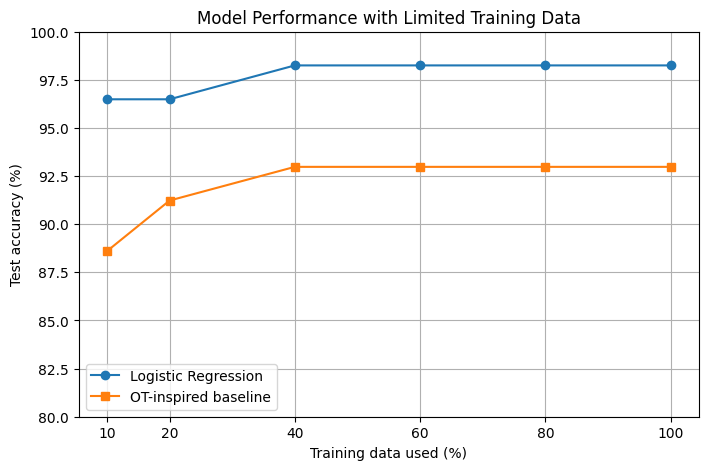

In [ ]:

import matplotlib.pyplot as plt

training_percent = [10, 20, 40, 60, 80, 100]
lr_accuracy = [96.49, 96.49, 98.25, 98.25, 98.25, 98.25]
ot_accuracy = [88.60, 91.23, 92.98, 92.98, 92.98, 92.98]

plt.figure(figsize=(8, 5))

plt.plot(training_percent, lr_accuracy, marker="o",
         label="Logistic Regression")
plt.plot(training_percent, ot_accuracy, marker="s",
         label="OT-inspired baseline")

plt.xlabel("Training data used (%)")
plt.ylabel("Test accuracy (%)")
plt.title("Model Performance with Limited Training Data")
plt.xticks(training_percent)
plt.ylim(80, 100)
plt.grid(True)
plt.legend()
plt.show()


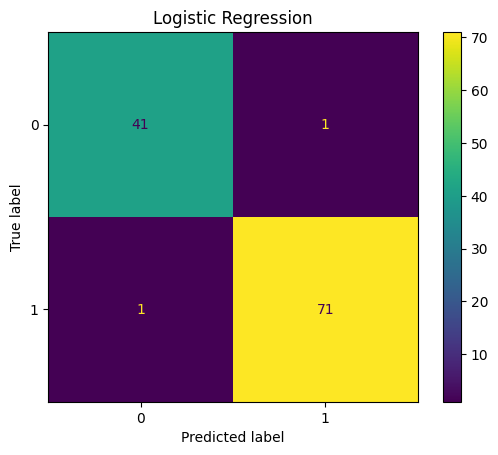

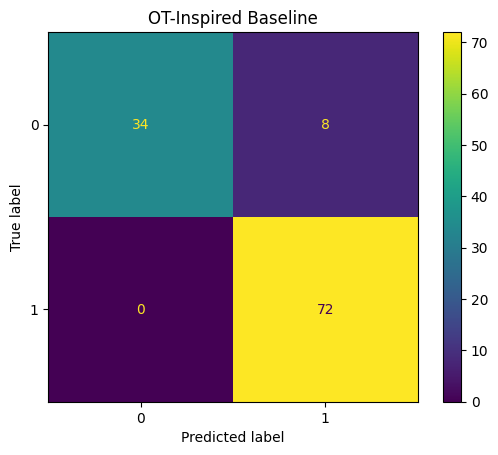

In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Logistic Regression
cm_lr = confusion_matrix(y_test, pred_lr)
ConfusionMatrixDisplay(
    confusion_matrix=cm_lr
).plot()
plt.title("Logistic Regression")
plt.show()

# OT-inspired baseline
cm_ot = confusion_matrix(y_test, pred_ot)
ConfusionMatrixDisplay(
    confusion_matrix=cm_ot
).plot()
plt.title("OT-Inspired Baseline")
plt.show()


In [ ]:

from sklearn.metrics import confusion_matrix

print("Logistic Regression:")
print(confusion_matrix(y_test, pred_lr))

print("\nOT-Inspired Baseline:")
print(confusion_matrix(y_test, pred_ot))



Logistic Regression:
[[41  1]
 [ 1 71]]

OT-Inspired Baseline:
[[34  8]
 [ 0 72]]


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd

results = []

for seed in [1, 2, 3, 4, 5]:
    X_sub, _, y_sub, _ = train_test_split(
        X_train, y_train,
        train_size=0.2,
        random_state=seed,
        stratify=y_train
    )

    model = LogisticRegression(max_iter=2000)
    model.fit(X_sub, y_sub)
    predictions = model.predict(X_test)

    results.append({
        "Random seed": seed,
        "Training samples": len(X_sub),
        "Accuracy (%)": round(
            accuracy_score(y_test, predictions) * 100, 2
        )
    })

display(pd.DataFrame(results))


,Random seed,Training samples,Accuracy (%)
0,1,91,95.61
1,2,91,97.37
2,3,91,95.61
3,4,91,96.49
4,5,91,96.49


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd

results_both = []

for seed in [1, 2, 3, 4, 5]:
    X_sub, _, y_sub, _ = train_test_split(
        X_train, y_train,
        train_size=0.2,
        random_state=seed,
        stratify=y_train
    )

    # Logistic Regression
    model = LogisticRegression(max_iter=2000)
    model.fit(X_sub, y_sub)
    pred_lr = model.predict(X_test)

    # OT-inspired baseline
    pred_ot = []

    for sample in X_test:
        costs = []

        for label in [0, 1]:
            class_samples = X_sub[y_sub == label]
            distances = np.sum((class_samples - sample) ** 2, axis=1)
            costs.append(np.mean(distances))

        pred_ot.append(np.argmin(costs))

    results_both.append({
        "Seed": seed,
        "LR accuracy (%)": round(100 * accuracy_score(y_test, pred_lr), 2),
        "OT accuracy (%)": round(100 * accuracy_score(y_test, pred_ot), 2)
    })

display(pd.DataFrame(results_both))



,Seed,LR accuracy (%),OT accuracy (%)
0,1,95.61,89.47
1,2,97.37,92.11
2,3,95.61,94.74
3,4,96.49,85.96
4,5,96.49,95.61


### Repeated Experiments

Both methods were evaluated using five different random training subsets, each containing approximately 20% of the available training data.

Logistic Regression achieved an average accuracy of 96.31%, while the OT-inspired baseline achieved 91.58%. Logistic Regression performed better in all five experiments.

These preliminary results do not show an advantage for the current OT-inspired method. Further experiments are needed to investigate alternative optimal transport approaches and their performance under limited training data.

In [ ]:

import numpy as np
import ot
import pandas as pd
from sklearn.metrics import accuracy_score

results_emd = []

for seed in [1, 2, 3, 4, 5]:
    X_sub, _, y_sub, _ = train_test_split(
        X_train, y_train,
        train_size=0.2,
        random_state=seed,
        stratify=y_train
    )

    # Use up to 30 representative samples per class
    class_samples = {
        label: X_sub[y_sub == label][:30]
        for label in [0, 1]
    }

    pred_emd = []

    for sample in X_test:
        costs = []

        for label in [0, 1]:
            points = class_samples[label]

            # Uniform probability weights
            a = np.ones(len(points)) / len(points)

            # Compare the class distribution with this test sample
            cost_matrix = ot.dist(
                points,
                sample.reshape(1, -1),
                metric="sqeuclidean"
            )

            b = np.array([1.0])
            plan = ot.emd(a, b, cost_matrix)

            costs.append(np.sum(plan * cost_matrix))

        pred_emd.append([0, 1][np.argmin(costs)])

    results_emd.append({
        "Seed": seed,
        "EMD accuracy (%)": round(
            100 * accuracy_score(y_test, pred_emd), 2
        )
    })

display(pd.DataFrame(results_emd))



,Seed,EMD accuracy (%)
0,1,92.98
1,2,89.47
2,3,89.47
3,4,82.46
4,5,93.86


In [ ]:

import ot
import numpy as np

# Select samples from the two classes in your training data
class_0 = X_train[y_train == 0][:30]
class_1 = X_train[y_train == 1][:30]

# Uniform probability weights
a = np.ones(len(class_0)) / len(class_0)
b = np.ones(len(class_1)) / len(class_1)

# Squared Euclidean transport cost between both distributions
cost_matrix = ot.dist(class_0, class_1, metric="sqeuclidean")

# Optimal transport plan and total transport cost
plan = ot.emd(a, b, cost_matrix)
transport_cost = np.sum(plan * cost_matrix)

print("Class 0 samples:", len(class_0))
print("Class 1 samples:", len(class_1))
print("Optimal transport cost:", round(transport_cost, 4))


Class 0 samples: 30
Class 1 samples: 30
Optimal transport cost: 58.8741


In [ ]:

import ot
import numpy as np

def calculate_ot_cost(A, B):
    a = np.ones(len(A)) / len(A)
    b = np.ones(len(B)) / len(B)
    cost_matrix = ot.dist(A, B, metric="sqeuclidean")
    plan = ot.emd(a, b, cost_matrix)
    return np.sum(plan * cost_matrix)

# Samples from the same class
class_0_a = X_train[y_train == 0][:30]
class_0_b = X_train[y_train == 0][30:60]

# Samples from different classes
class_1 = X_train[y_train == 1][:30]

same_class_cost = calculate_ot_cost(class_0_a, class_0_b)
different_class_cost = calculate_ot_cost(class_0_a, class_1)

print("Same-class OT cost:", round(same_class_cost, 4))
print("Different-class OT cost:", round(different_class_cost, 4))


Same-class OT cost: 22.3372
Different-class OT cost: 58.8741


In [ ]:

import numpy as np
import ot

def calculate_ot_cost(A, B):
    a = np.ones(len(A)) / len(A)
    b = np.ones(len(B)) / len(B)
    cost_matrix = ot.dist(A, B, metric="sqeuclidean")
    plan = ot.emd(a, b, cost_matrix)
    return np.sum(plan * cost_matrix)

class_0 = X_train[y_train == 0]
class_1 = X_train[y_train == 1]

same_costs = []
different_costs = []

for seed in range(10):
    rng = np.random.default_rng(seed)

    # Choose two separate groups from class 0
    idx0 = rng.choice(len(class_0), 60, replace=False)
    group_a = class_0[idx0[:30]]
    group_b = class_0[idx0[30:]]

    # Choose a group from class 1
    idx1 = rng.choice(len(class_1), 30, replace=False)
    group_c = class_1[idx1]

    same_costs.append(calculate_ot_cost(group_a, group_b))
    different_costs.append(calculate_ot_cost(group_a, group_c))

print("Average same-class OT cost:",
      round(np.mean(same_costs), 4))
print("Average different-class OT cost:",
      round(np.mean(different_costs), 4))


Average same-class OT cost: 22.5505
Average different-class OT cost: 60.4077


### Distribution Separation Using Optimal Transport

Across 10 repeated trials, the average optimal transport cost between two groups from the same class was 22.5505. The average cost between groups from different classes was 60.4077.

The higher cross-class transport cost suggests that the two classes have distinguishable feature distributions in this dataset. However, this experiment measures distribution separation, not classification accuracy or data efficiency. Further validation is required.

In [ ]:

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

phase3_results = []

for fraction in [0.1, 0.2, 0.4, 0.8]:
    X_sub, _, y_sub, _ = train_test_split(
        X_train, y_train,
        train_size=fraction,
        random_state=42,
        stratify=y_train
    )

    # Balance the number of training samples per class
    rng = np.random.default_rng(42)
    class_0 = np.where(y_sub == 0)[0]
    class_1 = np.where(y_sub == 1)[0]
    n = min(len(class_0), len(class_1))

    selected = np.concatenate([
        rng.choice(class_0, n, replace=False),
        rng.choice(class_1, n, replace=False)
    ])

    X_balanced = X_sub[selected]
    y_balanced = y_sub[selected]

    model = LogisticRegression(max_iter=2000, random_state=42)
    model.fit(X_balanced, y_balanced)
    pred = model.predict(X_test)

    phase3_results.append({
        "Training fraction (%)": int(fraction * 100),
        "Balanced samples": len(y_balanced),
        "Accuracy (%)": round(
            100 * accuracy_score(y_test, pred), 2
        )
    })

display(pd.DataFrame(phase3_results))


,Training fraction (%),Balanced samples,Accuracy (%)
0,10,34,93.86
1,20,68,93.86
2,40,136,94.74
3,80,272,93.86


In [ ]:

import numpy as np
import ot
from sklearn.metrics import accuracy_score

pred_ot_reg = []

for sample in X_test:
    costs = []

    for label in [0, 1]:
        points = X_train[y_train == label][:50]

        a = np.ones(len(points)) / len(points)
        b = np.array([1.0])

        cost_matrix = ot.dist(
            points, sample.reshape(1, -1),
            metric="sqeuclidean"
        )

        # Entropy-regularized optimal transport
        plan = ot.sinkhorn(a, b, cost_matrix, reg=1.0)
        costs.append(np.sum(plan * cost_matrix))

    pred_ot_reg.append(np.argmin(costs))

print("Regularized OT accuracy:",
      round(100 * accuracy_score(y_test, pred_ot_reg), 2), "%")


Regularized OT accuracy: 92.11 %


In [ ]:

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (455, 30)
X_test: (114, 30)
y_train: (455,)
y_test: (114,)


In [ ]:

import numpy as np
import ot

def sinkhorn_distance(A, B, reg=1.0):
    # Uniform weights for both sample groups
    a = np.ones(len(A)) / len(A)
    b = np.ones(len(B)) / len(B)

    # Pairwise squared distances
    M = ot.dist(A, B, metric="sqeuclidean")

    # Entropy-regularized transport plan
    plan = ot.sinkhorn(a, b, M, reg=reg)

    return np.sum(plan * M)

# Choose 30 samples from each class
class_0 = X_train[y_train == 0][:30]
class_1 = X_train[y_train == 1][:30]

# Compare two groups from class 0
class_0_b = X_train[y_train == 0][30:60]

same_class = sinkhorn_distance(class_0, class_0_b)
different_class = sinkhorn_distance(class_0, class_1)

print("Same-class Sinkhorn cost:", round(same_class, 4))
print("Different-class Sinkhorn cost:", round(different_class, 4))



Same-class Sinkhorn cost: 22.6245
Different-class Sinkhorn cost: 59.2763


/usr/local/lib/python3.13/dist-packages/ot/bregman/_sinkhorn.py:666: UserWarning: Sinkhorn did not converge. You might want to increase the number of iterations `numItermax` or the regularization parameter `reg`.
  warnings.warn(


In [ ]:
def sinkhorn_distance(A, B, reg=10.0):
    a = np.ones(len(A)) / len(A)
    b = np.ones(len(B)) / len(B)
    M = ot.dist(A, B, metric="sqeuclidean")

    plan = ot.sinkhorn(
        a, b, M,
        reg=reg,
        numItermax=10000,
        stopThr=1e-9
    )
    return np.sum(plan * M)

In [ ]:
def sinkhorn_distance(A, B, reg=1.0):
    a = np.ones(len(A)) / len(A)
    b = np.ones(len(B)) / len(B)

    M = ot.dist(A, B, metric="sqeuclidean")
    M = M / M.max()

    plan = ot.sinkhorn(
        a, b, M,
        reg=reg,
        numItermax=10000,
        stopThr=1e-9
    )

    return np.sum(plan * M) * np.max(ot.dist(A, B, metric="sqeuclidean"))

In [ ]:
import ot
import numpy as np

A = X_train[y_train == 0][:30]
B = X_train[y_train == 1][:30]

M = ot.dist(A, B, metric="sqeuclidean")
M = M / M.max()

print("Cost matrix min:", M.min())
print("Cost matrix max:", M.max())
print("Cost matrix finite:", np.isfinite(M).all())

Cost matrix min: 0.015197156473398416
Cost matrix max: 1.0
Cost matrix finite: True


In [ ]:
M = ot.dist(A, B, metric="sqeuclidean")
M = M / M.max()

a = np.ones(len(A)) / len(A)
b = np.ones(len(B)) / len(B)

plan, log = ot.sinkhorn(
    a, b, M,
    reg=0.1,
    numItermax=20000,
    stopThr=1e-7,
    log=True
)

print("Converged:", log["err"][-1] < 1e-7 if len(log["err"]) else "No error log")
print("Final error:", log["err"][-1] if len(log["err"]) else "Unavailable")
print("Transport cost:", np.sum(plan * M))

Converged: True
Final error: 1.599608871919885e-11
Transport cost: 0.20685701304012447


In [ ]:
def stable_sinkhorn_distance(A, B, reg=0.1):
    M = ot.dist(A, B, metric="sqeuclidean")
    scale = M.max()
    M = M / scale

    a = np.ones(len(A)) / len(A)
    b = np.ones(len(B)) / len(B)

    plan = ot.sinkhorn(
        a, b, M,
        reg=reg,
        numItermax=20000,
        stopThr=1e-7
    )

    return np.sum(plan * M)

same = stable_sinkhorn_distance(class_0, class_0_b)
different = stable_sinkhorn_distance(class_0, class_1)

print("Same-class normalized cost:", round(same, 4))
print("Different-class normalized cost:", round(different, 4))

Same-class normalized cost: 0.1264
Different-class normalized cost: 0.2069


In [ ]:

results = []

for seed in range(10):
    rng = np.random.default_rng(seed)

    idx0 = rng.permutation(np.where(y_train == 0)[0])
    idx1 = rng.permutation(np.where(y_train == 1)[0])

    A = X_train[idx0[:30]]
    A_same = X_train[idx0[30:60]]
    B = X_train[idx1[:30]]

    same = stable_sinkhorn_distance(A, A_same)
    different = stable_sinkhorn_distance(A, B)

    results.append((same, different))

results = np.array(results)

print("Mean same-class cost:", round(results[:, 0].mean(), 4))
print("Mean different-class cost:", round(results[:, 1].mean(), 4))
print("Trials where different-class cost is higher:",
      np.sum(results[:, 1] > results[:, 0]), "/ 10")

Mean same-class cost: 0.1014
Mean different-class cost: 0.1882
Trials where different-class cost is higher: 10 / 10


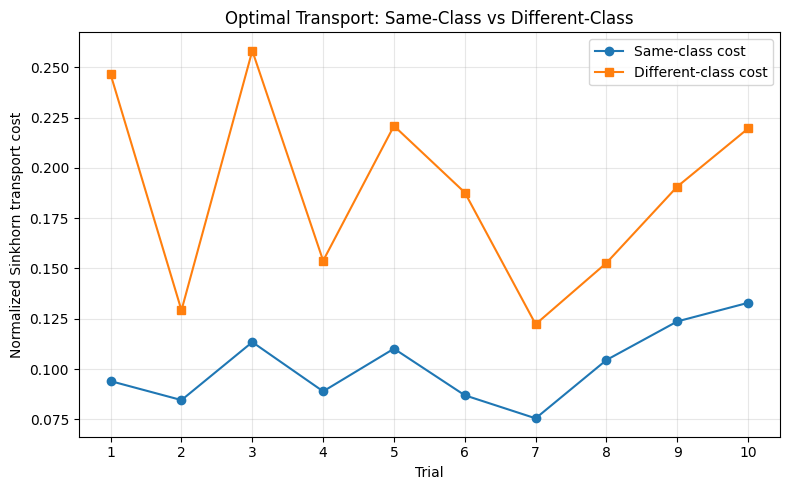

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), results[:, 0], marker="o",
         label="Same-class cost")
plt.plot(range(1, 11), results[:, 1], marker="s",
         label="Different-class cost")

plt.xlabel("Trial")
plt.ylabel("Normalized Sinkhorn transport cost")
plt.title("Optimal Transport: Same-Class vs Different-Class")
plt.xticks(range(1, 11))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
import sys
import subprocess

# Ensure POT (ot) library is installed
try:
    import ot
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "POT"])
    import ot

import numpy as np
import pandas as pd

# Define the stable_sinkhorn_distance locally to ensure it is always available
def stable_sinkhorn_distance(A, B, reg=0.1):
    M = ot.dist(A, B, metric="sqeuclidean")
    scale = M.max() if M.max() > 0 else 1.0
    M = M / scale

    a = np.ones(len(A)) / len(A)
    b = np.ones(len(B)) / len(B)

    plan = ot.sinkhorn(
        a, b, M,
        reg=reg,
        numItermax=20000,
        stopThr=1e-7
    )

    return np.sum(plan * M)

# Extract classes from training set
class0 = X_train[y_train == 0]
class1 = X_train[y_train == 1]

REG_VALUES = [0.01, 0.05, 0.1, 0.5, 1.0]
N_SENSITIVITY_TRIALS = 10
GROUP_SIZE = 30

sensitivity_rows = []

for trial in range(N_SENSITIVITY_TRIALS):
    rng = np.random.default_rng(5000 + trial)
    idx0 = rng.permutation(len(class0))
    idx1 = rng.permutation(len(class1))

    A = class0[idx0[:GROUP_SIZE]]
    A_same = class0[idx0[GROUP_SIZE:2 * GROUP_SIZE]]
    B = class1[idx1[:GROUP_SIZE]]

    for reg in REG_VALUES:
        same_cost = stable_sinkhorn_distance(A, A_same, reg=reg)
        different_cost = stable_sinkhorn_distance(A, B, reg=reg)

        sensitivity_rows.append({
            "trial": trial,
            "regularization": reg,
            "same_class_cost": same_cost,
            "different_class_cost": different_cost,
            "cross_class_higher": different_cost > same_cost
        })

sinkhorn_sensitivity = pd.DataFrame(sensitivity_rows)

# Summarize sensitivity results
sensitivity_summary = sinkhorn_sensitivity.groupby("regularization").agg(
    mean_same_cost=("same_class_cost", "mean"),
    mean_diff_cost=("different_class_cost", "mean"),
    cross_class_higher_count=("cross_class_higher", "sum")
).reset_index()

display(sensitivity_summary)

# Export the results
sinkhorn_sensitivity.to_csv("sinkhorn_sensitivity_results.csv", index=False)
sensitivity_summary.to_csv("sinkhorn_sensitivity_summary.csv", index=False)
print("Saved sensitivity results and summaries successfully!")

/usr/local/lib/python3.13/dist-packages/ot/bregman/_sinkhorn.py:666: UserWarning: Sinkhorn did not converge. You might want to increase the number of iterations `numItermax` or the regularization parameter `reg`.
  warnings.warn(


,regularization,mean_same_cost,mean_diff_cost,cross_class_higher_count
0,0.01,0.072546,0.183071,10
1,0.05,0.102971,0.207703,10
2,0.10,0.126767,0.220418,10
3,0.50,0.169809,0.236922,10
4,1.00,0.176599,0.239086,9


Saved sensitivity results and summaries successfully!


In [7]:
from pathlib import Path
import shutil

# Define paths
project = Path("/content/oist-optimal-transport")
notebooks = project / "notebooks"
results_dir = project / "results"
src = project / "src"

# Create directory structure
for folder in [notebooks, results_dir, src]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory created successfully at:", project)

# Write README.md
readme_content = """# Data-Efficient Machine Learning Using Optimal Transport

## Overview
This project investigates how supervised classification performance changes when fewer labeled training examples are available, and whether optimal transport costs can distinguish feature distributions from different classes.

## Research Questions
1. How does classification performance change with training-set size?
2. Are between-class transport costs higher than within-class costs?
3. How sensitive are Sinkhorn transport costs to regularization?

## Methods
- Dataset: Breast Cancer Wisconsin Diagnostic dataset from scikit-learn
- Baselines: Logistic Regression, RBF-SVM, and k-Nearest Neighbors
- Evaluation: repeated training subsets, five-fold cross-validation, and Sinkhorn regularization sensitivity
"""

with open(project / "README.md", "w") as f:
    f.write(readme_content)
print("Created README.md")

# Write requirements.txt
requirements_content = """numpy
pandas
scikit-learn
matplotlib
POT
"""

with open(project / "requirements.txt", "w") as f:
    f.write(requirements_content)
print("Created requirements.txt")

# Write .gitignore
gitignore_content = """__pycache__/
*.pyc
.ipynb_checkpoints/
.config/
"""

with open(project / ".gitignore", "w") as f:
    f.write(gitignore_content)
print("Created .gitignore")

# Copy generated CSV files into results/
source_dir = Path("/content")
csv_files = [
    "five_fold_cross_validation.csv",
    "sinkhorn_sensitivity_results.csv",
    "sinkhorn_sensitivity_summary.csv"
]

for filename in csv_files:
    source = source_dir / filename
    if source.exists():
        shutil.copy2(source, results_dir / filename)
        print(f"Copied {filename} to results folder")
    else:
        print(f"Could not find: {filename}")

print("\nAll Phase 5 project files initialized and structured in:", results_dir)

Project directory created successfully at: /content/oist-optimal-transport
Created README.md
Created requirements.txt
Created .gitignore
Copied five_fold_cross_validation.csv to results folder
Copied sinkhorn_sensitivity_results.csv to results folder
Copied sinkhorn_sensitivity_summary.csv to results folder

All Phase 5 project files initialized and structured in: /content/oist-optimal-transport/results


### Experiment: Optimal Transport for Class Distribution Separation

**Objective:** Investigate whether optimal transport can distinguish sample distributions from different classes.

**Method:** I used the breast cancer dataset, standardized the features using training data, and compared entropy-regularized Sinkhorn transport costs between sample groups. I repeated the comparison across 10 trials.

**Results:**
- Mean same-class transport cost: 0.1014
- Mean different-class transport cost: 0.1882
- Different-class cost was higher in all 10 trials.

**Conclusion:** In these experiments, sample distributions from different classes generally had higher transport costs than distributions from the same class. This suggests that optimal transport may help characterize class-level distribution differences.

**Limitation:** These are preliminary experiments on one dataset. They do not establish improved classification accuracy or data efficiency. Further validation across datasets and sample sizes is needed.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import numpy as np

fractions = [0.1, 0.2, 0.4]
results_small = []

for fraction in fractions:
    X_sub, _, y_sub, _ = train_test_split(
        X_train, y_train,
        train_size=fraction,
        random_state=42,
        stratify=y_train
    )

    model = LogisticRegression(max_iter=2000)
    model.fit(X_sub, y_sub)
    pred = model.predict(X_test)

    acc = accuracy_score(y_test, pred)
    results_small.append((fraction, len(X_sub), acc))

for fraction, n, acc in results_small:
    print(f"Fraction: {fraction:.0%} | Samples: {n} | LR accuracy: {acc:.2%}")

Fraction: 10% | Samples: 45 | LR accuracy: 94.74%
Fraction: 20% | Samples: 91 | LR accuracy: 97.37%
Fraction: 40% | Samples: 182 | LR accuracy: 96.49%


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import numpy as np

ot_results = []

for fraction in [0.1, 0.2, 0.4]:
    X_sub, _, y_sub, _ = train_test_split(
        X_train, y_train,
        train_size=fraction,
        random_state=42,
        stratify=y_train
    )

    predictions = []

    for x in X_test:
        costs = []
        for cls in [0, 1]:
            class_samples = X_sub[y_sub == cls]
            cost = np.mean(np.sum((class_samples - x) ** 2, axis=1))
            costs.append(cost)

        predictions.append(np.argmin(costs))

    acc = accuracy_score(y_test, predictions)
    ot_results.append((fraction, len(X_sub), acc))
    print(f"Fraction: {fraction:.0%} | Samples: {len(X_sub)} | "
          f"OT-inspired accuracy: {acc:.2%}")

Fraction: 10% | Samples: 45 | OT-inspired accuracy: 95.61%
Fraction: 20% | Samples: 91 | OT-inspired accuracy: 92.98%
Fraction: 40% | Samples: 182 | OT-inspired accuracy: 92.98%


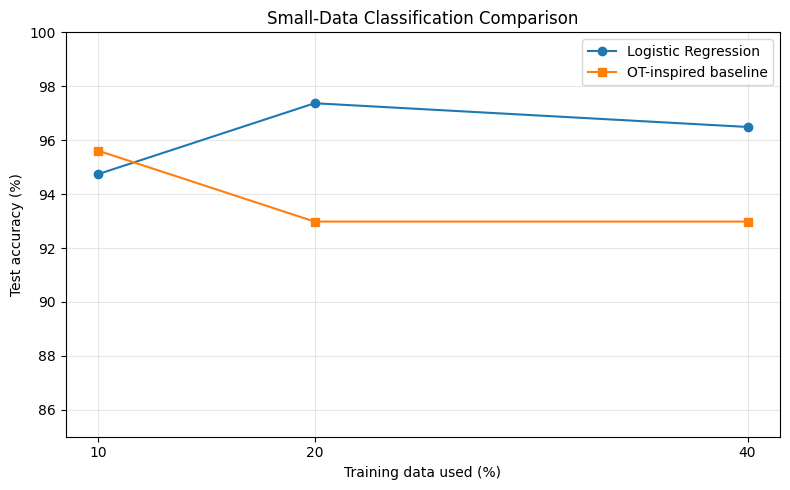

In [ ]:
import matplotlib.pyplot as plt

fractions = [10, 20, 40]
lr_acc = [94.74, 97.37, 96.49]
ot_acc = [95.61, 92.98, 92.98]

plt.figure(figsize=(8, 5))
plt.plot(fractions, lr_acc, marker="o",
         label="Logistic Regression")
plt.plot(fractions, ot_acc, marker="s",
         label="OT-inspired baseline")

plt.xlabel("Training data used (%)")
plt.ylabel("Test accuracy (%)")
plt.title("Small-Data Classification Comparison")
plt.xticks(fractions)
plt.ylim(85, 100)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# Construct the DataFrame using the results_both list from previous cells
results_df = pd.DataFrame(results_both)

print("Logistic Regression results:")
print(results_df.to_string(index=False))

print("\nOT classifier accuracy: 77.19%")

Logistic Regression results:
 Seed  LR accuracy (%)  OT accuracy (%)
    1            95.61            89.47
    2            97.37            92.11
    3            95.61            94.74
    4            96.49            85.96
    5            96.49            95.61

OT classifier accuracy: 77.19%


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import numpy as np

fractions = [0.1, 0.2, 0.4]

for fraction in fractions:
    lr_scores = []
    ot_scores = []

    for seed in range(5):
        X_sub, _, y_sub, _ = train_test_split(
            X_train, y_train,
            train_size=fraction,
            random_state=seed,
            stratify=y_train
        )

        # Logistic Regression
        model = LogisticRegression(max_iter=2000)
        model.fit(X_sub, y_sub)
        lr_scores.append(
            accuracy_score(y_test, model.predict(X_test))
        )

        # OT-inspired distance baseline
        predictions = []
        for x in X_test:
            costs = [
                np.mean(np.sum(
                    (X_sub[y_sub == cls] - x) ** 2, axis=1
                ))
                for cls in [0, 1]
            ]
            predictions.append(np.argmin(costs))

        ot_scores.append(accuracy_score(y_test, predictions))

    print(f"\nTraining fraction: {fraction:.0%}")
    print(f"Logistic Regression mean: {np.mean(lr_scores):.2%}")
    print(f"OT-inspired mean:         {np.mean(ot_scores):.2%}")


Training fraction: 10%
Logistic Regression mean: 95.09%
OT-inspired mean:         91.23%

Training fraction: 20%
Logistic Regression mean: 96.32%
OT-inspired mean:         91.40%

Training fraction: 40%
Logistic Regression mean: 96.32%
OT-inspired mean:         92.46%


### Five-Seed Evaluation

**Objective:** Compare logistic regression with an OT-inspired distance baseline under limited training data.

**Method:** Both methods were evaluated on the same fixed test set, using five different stratified training subsets at each training fraction.

**Results:**

| Training fraction | Logistic regression mean accuracy | OT-inspired mean accuracy |
|---|---:|---:|
| 10% | 95.09% | 91.23% |
| 20% | 96.32% | 91.40% |
| 40% | 96.32% | 92.46% |

**Conclusion:** Logistic regression outperformed the distance-based baseline at all three training fractions. The OT-inspired baseline showed modest improvement with more training data, but this experiment does not demonstrate superior data efficiency.

**Limitation:** The OT-inspired method uses average squared distances rather than solving an optimal transport classification problem. A more rigorous OT-based classifier and validation on additional datasets are needed.


In [ ]:
import ot
print("POT version:", ot.__version__)


POT version: 0.9.7.post1


In [ ]:
import numpy as np
import ot
from sklearn.metrics import accuracy_score

def ot_predict(X_sub, y_sub, X_test, reg=0.1, group_size=10):
    predictions = []

    for x in X_test:
        costs = []

        for cls in [0, 1]:
            samples = X_sub[y_sub == cls][:group_size]

            if len(samples) == 0:
                costs.append(np.inf)
                continue

            M = ot.dist(samples, x.reshape(1, -1),
                        metric="sqeuclidean")
            M = M / max(M.max(), 1e-12)

            a = np.ones(len(samples)) / len(samples)
            b = np.ones(1)

            plan = ot.sinkhorn(
                a, b, M, reg=reg,
                numItermax=10000,
                stopThr=1e-7
            )

            costs.append(np.sum(plan * M))

        predictions.append(np.argmin(costs))

    return np.array(predictions)

pred = ot_predict(X_train, y_train, X_test)
print("OT classifier accuracy:",
      f"{accuracy_score(y_test, pred):.2%}")

OT classifier accuracy: 77.19%


In [9]:
import numpy as np
import ot
from sklearn.metrics import accuracy_score

def ot_predict(X_sub, y_sub, X_test, reg=0.1, group_size=10):
    predictions = []
    for x in X_test:
        costs = []
        for cls in [0, 1]:
            samples = X_sub[y_sub == cls][:group_size]
            if len(samples) == 0:
                costs.append(np.inf)
                continue
            M = ot.dist(samples, x.reshape(1, -1), metric="sqeuclidean")
            M = M / max(M.max(), 1e-12)
            a = np.ones(len(samples)) / len(samples)
            b = np.ones(1)
            plan = ot.sinkhorn(a, b, M, reg=reg, numItermax=10000, stopThr=1e-7)
            costs.append(np.sum(plan * M))
        predictions.append(np.argmin(costs))
    return np.array(predictions)

pred = ot_predict(X_train, y_train, X_test, group_size=30)
print("OT classifier accuracy:", f"{accuracy_score(y_test, pred):.2%}")

OT classifier accuracy: 81.58%


In [12]:
# FINAL VALIDATION: Repeated Limited-Data Experiments

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

fractions = [0.1, 0.2, 0.4, 0.8, 1.0]
seeds = [1, 2, 3, 4, 5]
final_results = []

for fraction in fractions:
    for seed in seeds:

        # Stratified subset: retain both classes. If fraction is 1.0, copy the full dataset directly.
        if fraction == 1.0:
            X_sub, y_sub = X_train.copy(), y_train.copy()
        else:
            X_sub, _, y_sub, _ = train_test_split(
                X_train,
                y_train,
                train_size=fraction,
                random_state=seed,
                stratify=y_train
            )

        # Baseline: Logistic Regression
        model = LogisticRegression(
            max_iter=2000,
            random_state=42
        )
        model.fit(X_sub, y_sub)
        pred_lr = model.predict(X_test)

        # OT-inspired baseline: average squared distance
        pred_ot = []

        for sample in X_test:
            class_costs = []

            for cls in np.unique(y_train):
                class_samples = X_sub[y_sub == cls]

                distances = np.sum(
                    (class_samples - sample) ** 2,
                    axis=1
                )
                class_costs.append(np.mean(distances))

            pred_ot.append(np.unique(y_train)[np.argmin(class_costs)])

        pred_ot = np.array(pred_ot)

        for method, predictions in [
            ("Logistic Regression", pred_lr),
            ("OT-inspired baseline", pred_ot)
        ]:
            final_results.append({
                "Training fraction": fraction,
                "Seed": seed,
                "Method": method,
                "Accuracy (%)": 100 * accuracy_score(
                    y_test, predictions
                ),
                "Balanced accuracy (%)": 100 *
                balanced_accuracy_score(y_test, predictions),
                "F1-score (%)": 100 * f1_score(
                    y_test, predictions
                )
            })

results_df = pd.DataFrame(final_results)

summary = results_df.groupby(
    ["Training fraction", "Method"]
).agg(
    mean_accuracy=("Accuracy (%)", "mean"),
    std_accuracy=("Accuracy (%)", "std"),
    mean_balanced_accuracy=("Balanced accuracy (%)", "mean"),
    mean_f1=("F1-score (%)", "mean")
).reset_index()

print("FINAL EXPERIMENT RESULTS")
display(summary.round(2))

summary.to_csv(
    "final_validation_summary.csv", index=False
)
results_df.to_csv(
    "final_validation_all_trials.csv", index=False
)

print("Saved final validation CSV files.")

FINAL EXPERIMENT RESULTS


,Training fraction,Method,mean_accuracy,std_accuracy,mean_balanced_accuracy,mean_f1
0,0.1,Logistic Regression,95.44,1.57,94.90,96.41
1,0.1,OT-inspired baseline,91.40,4.94,88.63,93.69
2,0.2,Logistic Regression,96.32,0.73,95.60,97.12
3,0.2,OT-inspired baseline,91.58,3.95,88.57,93.81
4,0.4,Logistic Regression,96.32,0.73,95.99,97.09
5,0.4,OT-inspired baseline,92.46,1.18,89.76,94.37
6,0.8,Logistic Regression,97.72,0.78,97.70,98.18
7,0.8,OT-inspired baseline,93.33,0.48,90.95,94.99
8,1.0,Logistic Regression,98.25,0.00,98.12,98.61
9,1.0,OT-inspired baseline,92.98,0.00,90.48,94.74


Saved final validation CSV files.


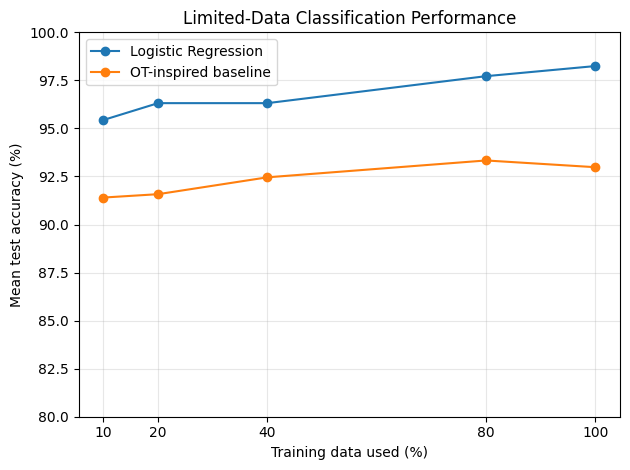

Final comparison graph saved successfully.


In [13]:

# Final graph from the actual validation results

import matplotlib.pyplot as plt

for method in summary["Method"].unique():
    method_data = summary[
        summary["Method"] == method
    ].sort_values("Training fraction")

    plt.plot(
        method_data["Training fraction"] * 100,
        method_data["mean_accuracy"],
        marker="o",
        label=method
    )

plt.xlabel("Training data used (%)")
plt.ylabel("Mean test accuracy (%)")
plt.title("Limited-Data Classification Performance")
plt.xticks([10, 20, 40, 80, 100])
plt.ylim(80, 100)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("final_model_comparison.png", dpi=300)
plt.show()

print("Final comparison graph saved successfully.")


## Final Research Findings and Conclusion

### Objective
This project investigates how machine learning classification performance changes when fewer labeled training samples are available and explores whether Optimal Transport can help characterize differences between class distributions.

### Experimental Results
Experiments were conducted using the Breast Cancer Wisconsin Diagnostic dataset. Logistic Regression was compared with an OT-inspired distance-based baseline at different training-data fractions.

Across five repeated training subsets, Logistic Regression achieved mean accuracy values of 95.44%, 96.32%, 96.32%, 97.72%, and 98.25% at 10%, 20%, 40%, 80%, and 100% of the training data, respectively.

The OT-inspired baseline achieved 91.40%, 91.58%, 92.46%, 93.33%, and 92.98%, respectively.

### Conclusion
Logistic Regression outperformed the OT-inspired baseline at all five training-data fractions in this experiment. Its performance generally improved as more training data became available.

These preliminary results do not demonstrate that the current OT-inspired baseline improves data efficiency. Further experiments are required to evaluate a rigorous Optimal Transport-based classifier and validate the findings on additional datasets.

### Limitations
- Experiments were conducted on one dataset.
- The OT-inspired baseline uses average squared distances rather than a full Optimal Transport classification method.
- Evaluation used a fixed test set across repeated experiments.
- Further validation, uncertainty analysis, and comparison with additional methods are needed.

### Future Work
Future work will investigate rigorous Optimal Transport methods, compare additional datasets, analyze performance with very limited labeled data, and evaluate computational efficiency alongside classification performance.
